# Outcome branching ratios across the scattering grid

A "money plot" comparison of **every** outcome of the BH1$-$star $+$ central-BH scattering experiment,
showing how each channel's share depends on the five parameters
$\beta=r_{t,\rm bin}/r_p$, $M_\bullet$, $a_{\rm bin}$, $e$, and $v_\infty/v_{\rm orb}$, each **marginalised
over the other four**.

Two complementary normalisations:
1. **All outcomes (flybys included):** $f_X = N_X/N_{\rm tot}=\sigma_X/(\pi b_{\max}^2)$ — the fraction of
   *all* encounters ending in channel $X$.  Flybys dominate, so this shows absolute branching.
2. **Strong channels only (flybys excluded):** $g_X = N_X/N_{\rm strong}$ with
   $N_{\rm strong}=N_{\rm tot}-N_{\rm FLYBY}$ — the share *among* dynamically significant outcomes.

Error bars are binomial on each fraction.  The $\mu$TDE channel (`TDE:star2_by_bh1`) is drawn in bold.

**Statistics note.** The impact parameter is sampled $b^2\sim\mathcal U[0,b_{\max}^2]$, so simple
per-bin counting is the correct estimator.  The **$\beta$ panel is robust to the $b^2$ sampling** (it is
the conditional fraction $P(X\mid\beta)$), but the $M_\bullet/a/e/v$ panels **marginalise over $\beta$**
and therefore require the genuine $b^2$-uniform run — on a $\beta$-reweighted subsample those four panels
are biased.

## 1. Setup and the bundle

In [1]:
import os
import numpy as np, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 150,
    "font.size": 15, "axes.titlesize": 16, "axes.labelsize": 19,
    "legend.fontsize": 14, "xtick.labelsize": 15, "ytick.labelsize": 15,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.major.size": 6.5, "ytick.major.size": 6.5, "xtick.minor.size": 3.5, "ytick.minor.size": 3.5,
    "axes.grid": False, "axes.linewidth": 0.9, "figure.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "serif", "font.serif": ["cmr10", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True, "axes.unicode_minus": False,
})

# ----- log-axis tick helpers: major every dex, labels every 2 dex, minor ticks at 2-9 -----
def _label_even_pow(val, pos):
    if val <= 0: return ""
    ex = np.log10(val)
    if abs(ex-round(ex)) > 1e-3: return ""
    ex = int(round(ex)); return rf"$10^{{{ex}}}$" if ex % 2 == 0 else ""
def log_axis_dex(axis):
    axis.set_major_locator(mticker.LogLocator(base=10, numticks=500))
    axis.set_major_formatter(mticker.FuncFormatter(_label_even_pow))
    axis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2,10), numticks=500))
    axis.set_minor_formatter(mticker.NullFormatter())
def log_minor(axis):
    axis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2,10), numticks=500))
    axis.set_minor_formatter(mticker.NullFormatter())

BETA_MAX_PLOT = 1e3        # cut the penetration axis here (beyond ~1e3 is the sparse deep-plunge tail)

# ----- point this at your bundle -----
BUNDLE = os.environ.get("SMBH_BUNDLE", "../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
V1, C_KMS, m_bin = 29.7847, 299792.458, 11.0
FRAC_NODES = np.array([1e-3, 1e-2, 1e-1, 3e-1, 1.0, 3.0, 10.0])

# raw outcome label -> display name; order fixes colour/legend order
OUTMAP = [("FLYBY","FLYBY"), ("EXCHANGE_bh1","EXCHANGE_BH"), ("EXCHANGE_star2","EXCHANGE_star"),
          ("BOUND_TRIPLE","BOUND_TRIPLE"), ("TDE:star2_by_bh1","muTDE"), ("TDE:star2_by_SMBH","TDE_central"),
          ("PLUNGE:bh1_into_SMBH","PLUNGE_BH"), ("PLUNGE:star2_into_SMBH","PLUNGE_star"),
          ("IONIZATION","IONIZATION")]
RAW  = [r for r,_ in OUTMAP]; DISP = [d for _,d in OUTMAP]; NCH = len(DISP)

# per-channel style: colour-blind-safe (Okabe-Ito) + unique marker + line style (B/W-readable)
OI = dict(black="#000000", orange="#E69F00", skyblue="#56B4E9", green="#009E73",
          blue="#0072B2", vermillion="#D55E00", purple="#CC79A7", grey="#8C8C8C", gold="#B8860B")
CH_STYLE = {
    "FLYBY":(OI["grey"],"o","-"), "EXCHANGE_BH":(OI["orange"],"s","--"), "EXCHANGE_star":(OI["green"],"^","--"),
    "BOUND_TRIPLE":(OI["vermillion"],"D","-."), "muTDE":(OI["blue"],"o","-"), "TDE_central":(OI["purple"],"v",":"),
    "PLUNGE_BH":(OI["skyblue"],"P","--"), "PLUNGE_star":(OI["black"],"X",":"), "IONIZATION":(OI["gold"],"*","-."),
}
CH_DISPLAY = {"FLYBY":"flyby","EXCHANGE_BH":"exchange (BH)","EXCHANGE_star":"exchange (star)",
              "BOUND_TRIPLE":"bound triple","muTDE":r"$\mu$TDE","TDE_central":"TDE (central)",
              "PLUNGE_BH":"plunge (BH)","PLUNGE_star":"plunge (star)","IONIZATION":"ionization"}
def ch_lw(ch): return 2.3 if ch=="muTDE" else 1.2
def ch_ms(ch): return 5.5 if ch=="muTDE" else 4.0

with h5py.File(BUNDLE,"r") as f:
    R=f["results"]
    M=R["M_smbh"][:]; a=R["a_bin"][:]; e=R["e_bin"][:]
    beta=R["beta"][:]; vinf=R["v_inf"][:]; oc=R["outcome"][:].astype(str)
frac = FRAC_NODES[np.argmin(np.abs(np.log10(vinf/(V1*np.sqrt(m_bin/a)))[:,None]-np.log10(FRAC_NODES)[None,:]),axis=1)]
oidx = np.full(len(oc),-1,int)
for i,r in enumerate(RAW): oidx[oc==r]=i
print(f"{len(oc):,} encounters;  unmatched outcomes: {int(np.sum(oidx<0))}")
for k,d in enumerate(DISP): print(f"  {d:14s} {int(np.sum(oidx==k)):>10,d}  ({np.mean(oidx==k)*100:5.2f}%)")

27,633,319 encounters;  unmatched outcomes: 14
  FLYBY          22,224,906  (80.43%)
  EXCHANGE_BH     1,225,718  ( 4.44%)
  EXCHANGE_star   1,267,040  ( 4.59%)
  BOUND_TRIPLE      934,514  ( 3.38%)
  muTDE             788,113  ( 2.85%)
  TDE_central        71,246  ( 0.26%)
  PLUNGE_BH         597,662  ( 2.16%)
  PLUNGE_star       198,077  ( 0.72%)
  IONIZATION        326,029  ( 1.18%)


## 2. Marginalisation helper

For each axis we bin the encounters by that parameter (log bins for $\beta$; the native grid nodes for
$M_\bullet,a,e,v$), sum the per-outcome counts over everything else, and form the two fractions with
binomial errors.

In [2]:
def marginalize(x, axis_kind):
    """Return (centres, counts[nbin,NCH], Ntot[nbin]).  axis_kind: 'beta_log' or 'nodes' or 'e_nodes'."""
    valid = np.ones(len(x), bool)
    if axis_kind == "beta_log":
        edges = np.logspace(np.log10(0.1), np.log10(BETA_MAX_PLOT), 26)  # v2: tidal floor beta>=0.1 (rp_max=10 r_t)
        cen = np.sqrt(edges[:-1]*edges[1:]); nb = len(cen)
        ib = np.digitize(x, edges)-1
        valid = (ib >= 0) & (ib < nb)        # drop events beyond BETA_MAX_PLOT
    elif axis_kind == "e_nodes":
        cen = np.unique(x); nb = len(cen)
        ib = np.argmin(np.abs(x[:,None]-cen[None,:]), axis=1)
    else:                                   # positive node-valued (M, a, v): nearest in log
        cen = np.unique(x); nb = len(cen)
        ib = np.argmin(np.abs(np.log10(x)[:,None]-np.log10(cen)[None,:]), axis=1)
    C = np.zeros((nb, NCH))
    for k in range(NCH): C[:,k] = np.bincount(ib[(oidx==k)&valid], minlength=nb)[:nb]
    return cen, C, C.sum(1)

AXES = [("beta", beta, "beta_log", r"$\beta$", True),
        ("M",    M,    "nodes",    r"$M_\bullet\;[M_\odot]$",    True),
        ("a",    a,    "nodes",    r"$a_{\rm bin}\;[{\rm AU}]$", True),
        ("e",    e,    "e_nodes",  r"$e_{\rm bin}$",             False),
        ("v",    frac, "nodes",    r"$v_\infty/v_{\rm orb}$",    True)]
MARG = {name:(marginalize(x,kind)+(lab,logx)) for name,x,kind,lab,logx in AXES}
print("binned axes:", {k:v[1].shape for k,v in MARG.items()})

binned axes: {'beta': (25, 9), 'M': (19, 9), 'a': (13, 9), 'e': (12, 9), 'v': (7, 9)}


## 3. Figure 1 — all outcomes (flybys included): $f_X=N_X/N_{\rm tot}=\sigma_X/(\pi b_{\max}^2)$

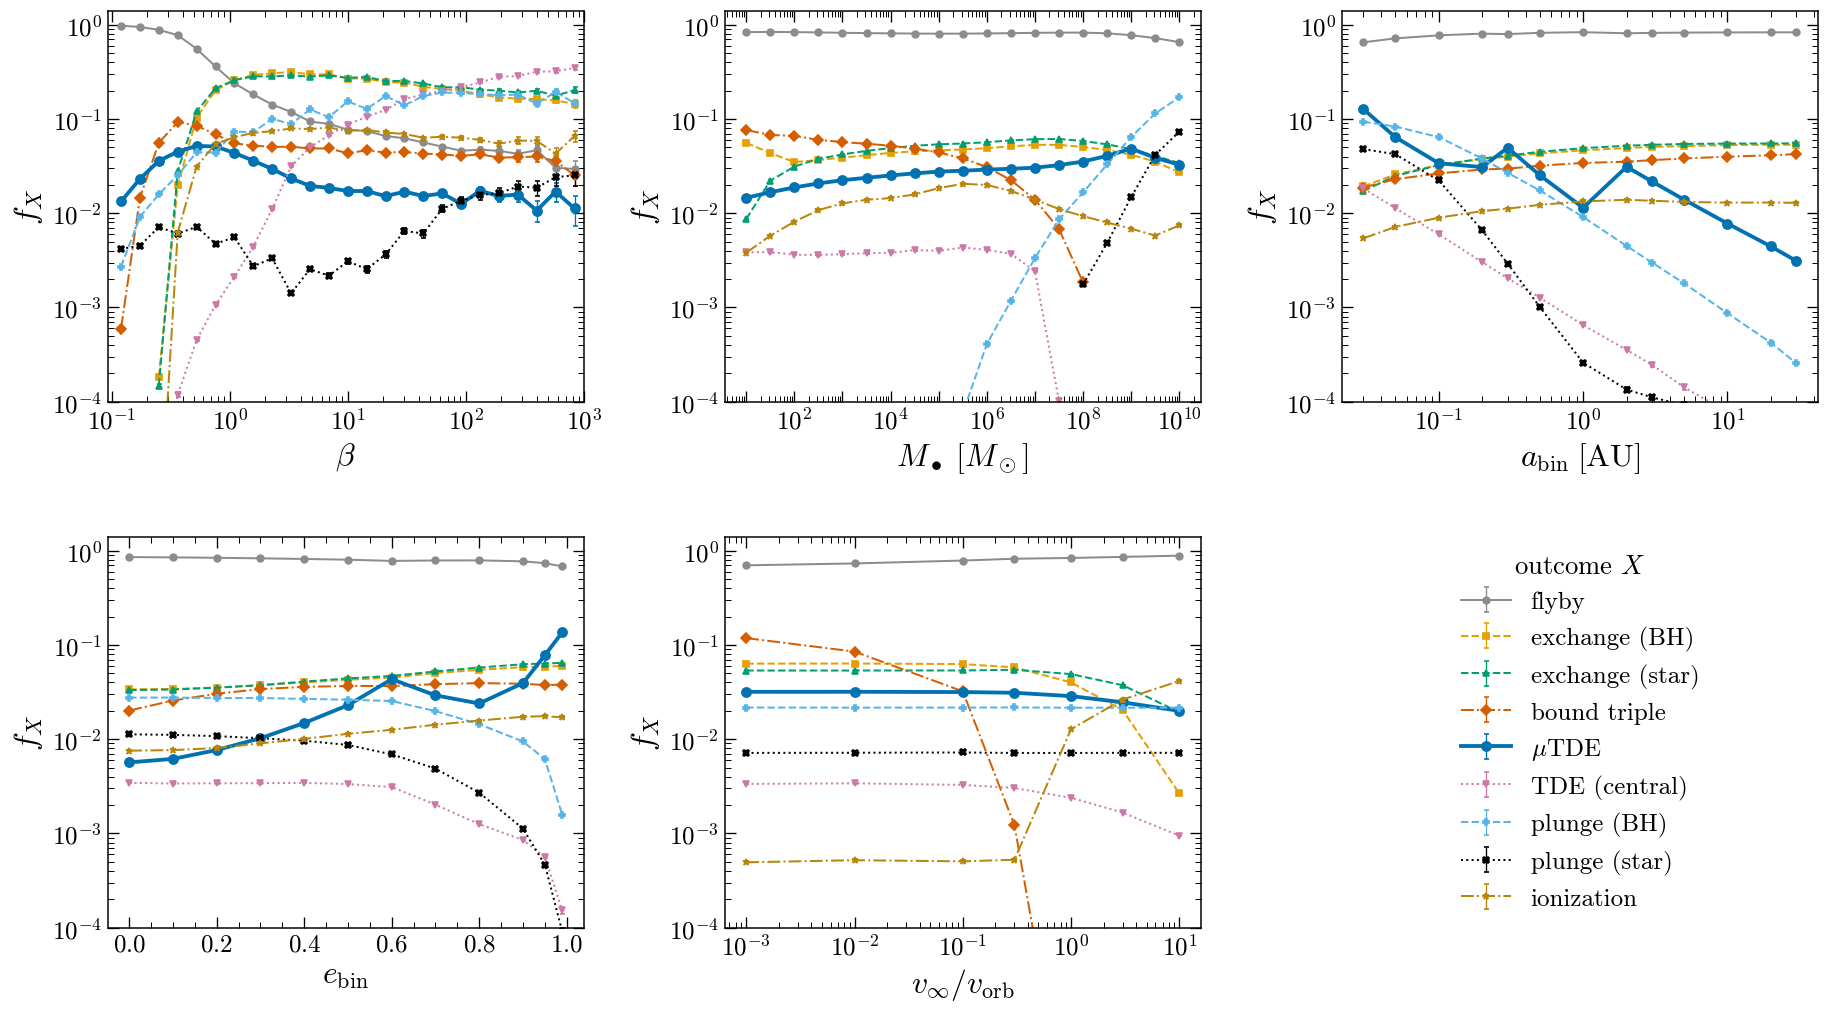

In [3]:
def money_plot(mode, fname, title):
    """mode='all' -> f_X=N_X/N_tot (incl flyby); mode='strong' -> g_X=N_X/N_strong (excl flyby)."""
    fig, axs = plt.subplots(2, 3, figsize=(15.5, 9.0))
    panel_order = ["beta","M","a","e","v"]
    chans = DISP if mode=="all" else [d for d in DISP if d!="FLYBY"]
    iflyby = DISP.index("FLYBY")
    for ip, name in enumerate(panel_order):
        ax = axs.flat[ip]; cen, C, Ntot, lab, logx = MARG[name]
        denom = Ntot if mode=="all" else (Ntot - C[:,iflyby])
        for d in chans:
            k = DISP.index(d); col,mk,ls = CH_STYLE[d]
            with np.errstate(divide="ignore", invalid="ignore"):
                fr = C[:,k]/denom; dfr = np.sqrt(np.clip(fr*(1-fr),0,None)/np.clip(denom,1,None))
            good = (C[:,k] > 0) & (denom > 0)
            ax.errorbar(cen[good], fr[good], yerr=dfr[good], marker=mk, ls=ls, color=col,
                        lw=ch_lw(d), ms=ch_ms(d), capsize=1.5, elinewidth=0.8, label=CH_DISPLAY[d])
        if logx:
            ax.set_xscale("log")
            # M_BH axis: labels every 2 dex, major ticks every 1 dex, minor ticks at 2-9; others: minor ticks
            log_axis_dex(ax.xaxis) if name == "M" else log_minor(ax.xaxis)
        if name == "beta": ax.set_xlim(cen.min()/1.3, BETA_MAX_PLOT)
        ax.set_yscale("log"); ax.set_ylim(1e-4, 1.4)
        ax.set_xlabel(lab); ax.set_ylabel(r"$f_X$")
        ax.set_box_aspect(0.82)
    # legend in the 6th panel
    axs.flat[5].axis("off")
    handles, labels = axs.flat[0].get_legend_handles_labels()
    axs.flat[5].legend(handles, labels, title=r"outcome $X$", loc="center", frameon=False, fontsize=15,
                       title_fontsize=16, ncol=1)
    fig.tight_layout()
    fig.savefig(fname+".png", bbox_inches="tight"); fig.savefig(fname+".pdf", bbox_inches="tight")
    plt.show()

money_plot("all", "branching_all",
           r"All outcomes (flybys included):  $f_X=N_X/N_{\rm tot}=\Sigma_X/(\pi b_{\max}^2)$")

## 4. Figure 2 — strong channels only (flybys excluded): $g_X=N_X/N_{\rm strong}$

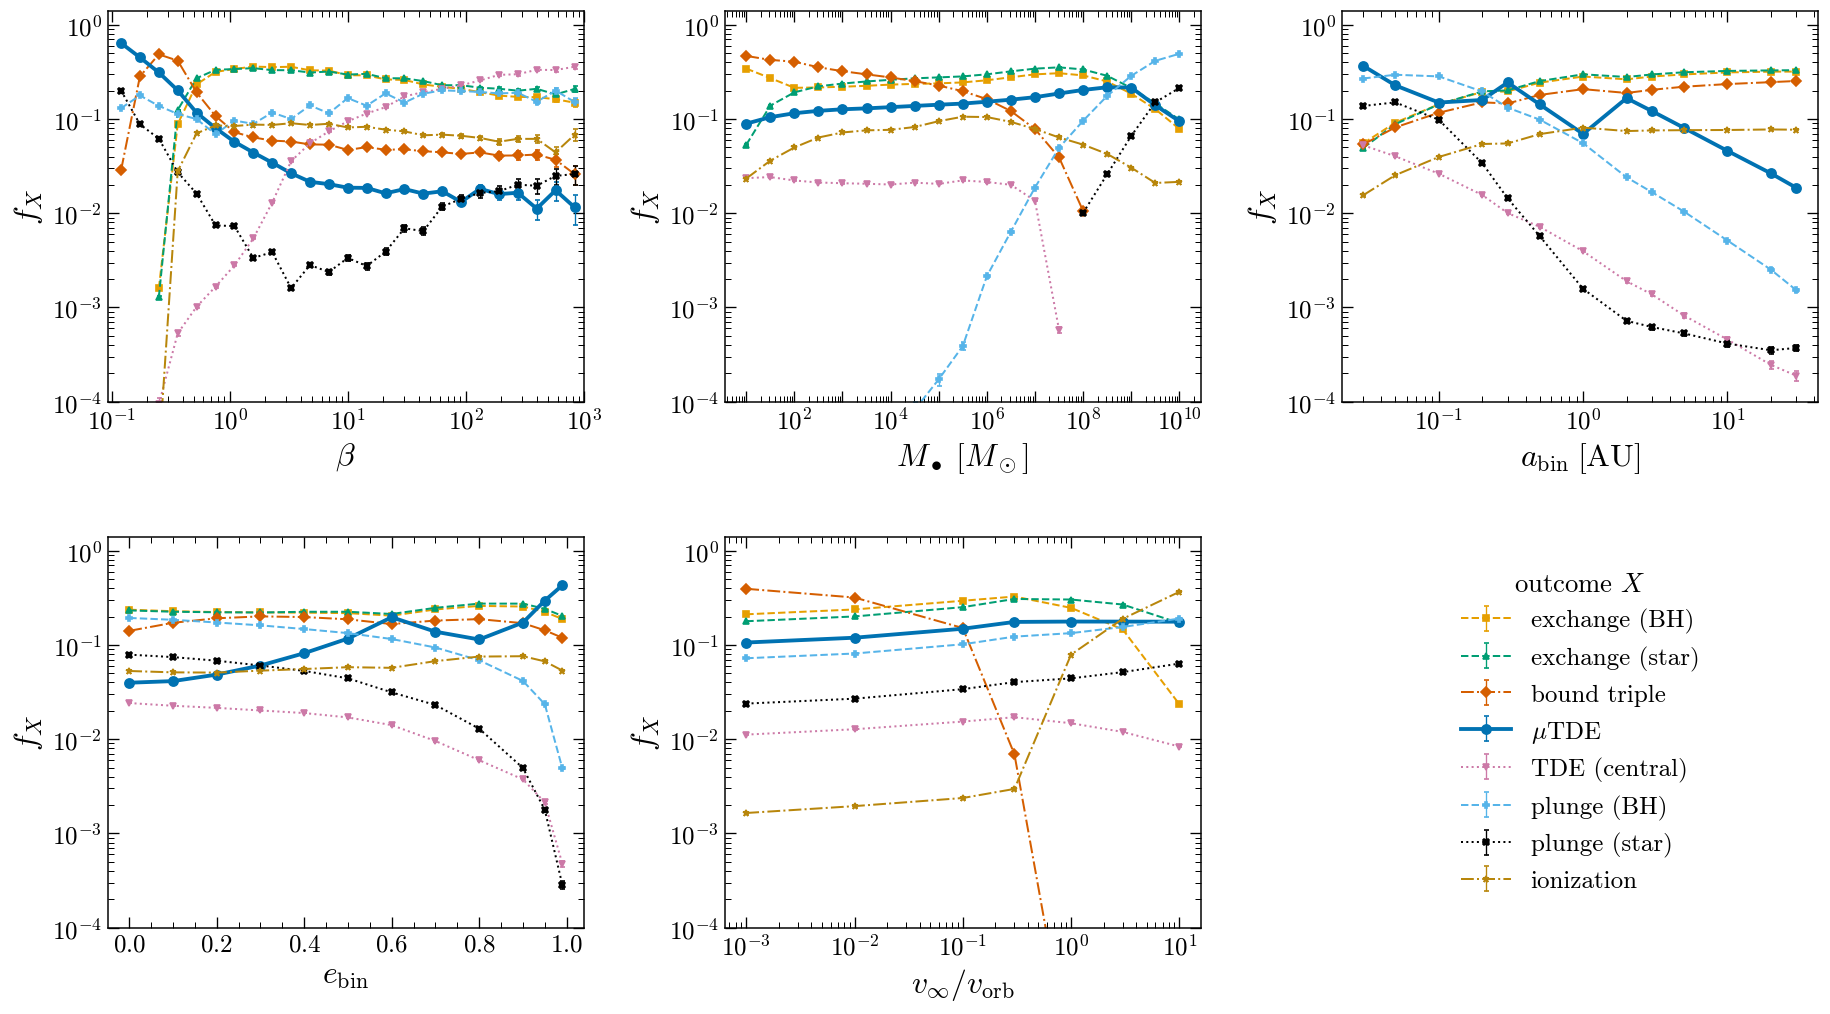

In [4]:
money_plot("strong", "branching_strong",
           r"Strong channels only (flybys excluded):  $g_X=N_X/N_{\rm strong}$")

## 5. Reading the plots

- The **$\beta$ panel** is the cleanest physical statement (conditional on penetration, independent of
  the $b^2$ sampling): shallow encounters ($\beta\lesssim1$) are almost all flybys, and as $\beta$ grows
  the strong channels switch on in order — exchanges and bound triples first, then $\mu$TDEs and plunges
  at the deepest penetrations.
- The **$M_\bullet$ panel** shows the central-object channels (`TDE_central`, `PLUNGE_*`) taking over at
  high $M_\bullet$ where the tidal sphere and $r_g$ grow.
- The **$a$ and $e$ panels** track the inner binary's fragility (wider / more eccentric binaries disrupt
  more readily), and the **$v$ panel** shows the soft/fast regime ($v_\infty\gtrsim v_{\rm orb}$) favouring
  ionisation.
- Quantitative values depend on the genuine $b^2\sim\mathcal U$ statistics for the
  $M_\bullet/a/e/v$ panels (see the note in \S0); rerun on the full bundle for publication numbers.

## Appendix: convergence of each outcome with the chosen $b_{\max}$

The outer cut is $r_{p,\max}=\max(5\,r_{t,\rm bin},\,8\,r_g)\Rightarrow
b_{\max}^2=r_{p,\max}^2+r_{\rm foc}\,r_{p,\max}$.  An outcome's cross section
$\sigma_X=(N_X/N)\pi b_{\max}^2$ is **converged** only if essentially no $X$ events occur near the
sampling edge $b\to b_{\max}$ — otherwise raising $b_{\max}$ would keep adding events and $\sigma_X$ is
truncated.  Because $b^2\sim\mathcal U[0,b_{\max}^2]$, the cumulative fraction of channel $X$ below an
impact parameter $b$ is exactly the normalised cross section,
$$\frac{\sigma_X(<b)}{\sigma_X(b_{\max})}=\frac{N_X(b'<b)}{N_X^{\rm tot}},$$
so each curve below is a convergence test: it should **plateau at 1 well before $b/b_{\max}=1$**.  The
right panel quantifies it as the fraction of each channel's events in the outer shell
$b/b_{\max}>0.9$ (small = converged; order-unity = that channel is truncated and its $b_{\max}$ should be
enlarged).  We reconstruct $b/b_{\max}$ per encounter from the stored $\beta$:
$r_p=r_{t,\rm bin}/\beta$, $b^2=r_p^2+r_{\rm foc}r_p$.

fraction of each outcome beyond b/b_max>0.9 (converged if << 1):
   FLYBY          0.2310
   EXCHANGE_BH    0.0000
   EXCHANGE_star  0.0000
   BOUND_TRIPLE   0.0005
   muTDE          0.1056
   TDE_central    0.0000
   PLUNGE_BH      0.0063
   PLUNGE_star    0.1435
   IONIZATION     0.0000


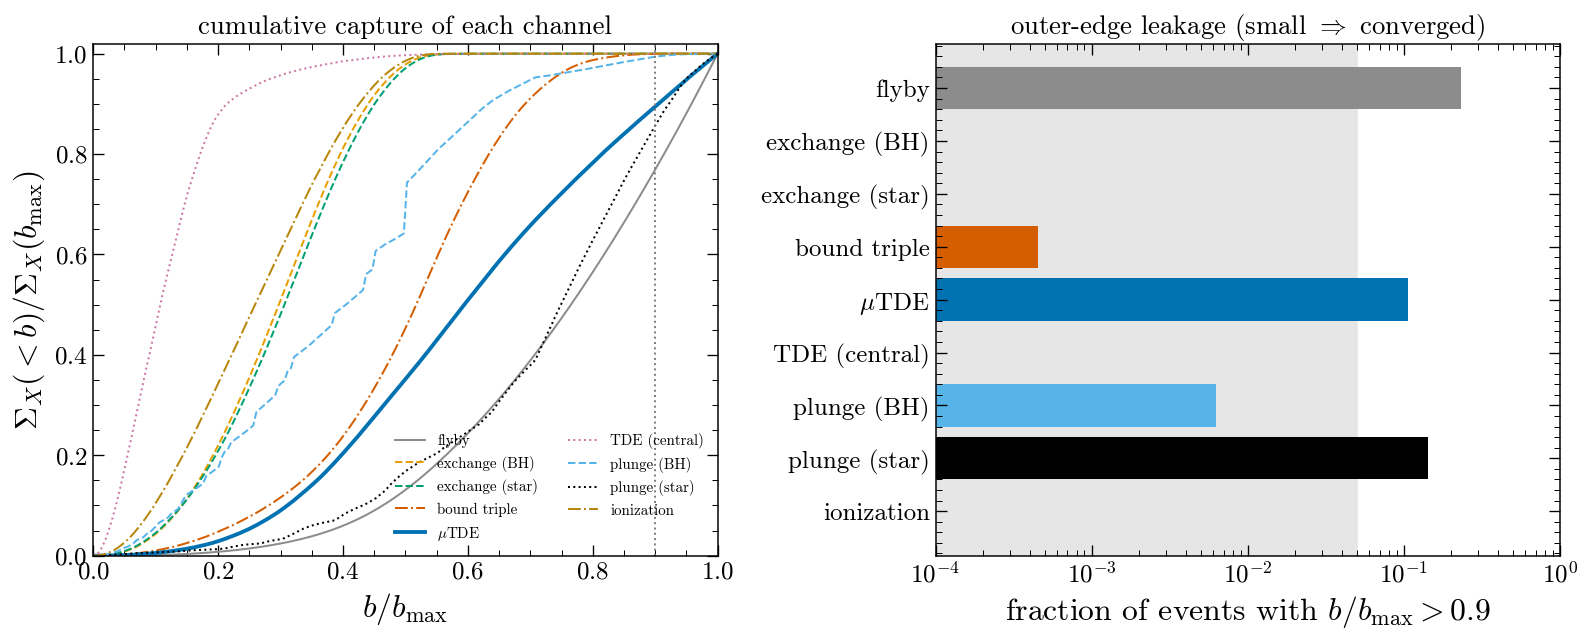

In [5]:
# per-encounter b/b_max from beta and the cell geometry
m_tot = M + m_bin
r_t   = a*(M/m_bin)**(1.0/3.0)
r_foc = 2.0*V1*V1*m_tot/(frac*V1*np.sqrt(m_bin/a))**2
r_g   = (V1*V1/(C_KMS*C_KMS))*m_tot
rp_max= np.maximum(10.0*r_t, 8.0*r_g)
b_max2= rp_max**2 + r_foc*rp_max
r_p   = r_t/beta
b2    = r_p**2 + r_foc*r_p
u     = np.clip(b2/b_max2, 0.0, 1.0)        # = (b/b_max)^2, uniform in [0,1] by construction
bb    = np.sqrt(u)                           # b / b_max

fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.4))
xs = np.linspace(0, 1, 200)
outer = {}
for d in DISP:
    k = DISP.index(d); col,mk,ls = CH_STYLE[d]
    bx = np.sort(bb[oidx==k])
    if bx.size == 0: continue
    F = np.searchsorted(bx, xs, side="right")/bx.size      # cumulative fraction below b/b_max
    ax[0].plot(xs, F, ls=ls, color=col, lw=ch_lw(d), label=CH_DISPLAY[d])
    outer[d] = np.mean(bx > 0.9)
ax[0].axvline(0.9, color="0.5", ls=":", lw=1.2)
ax[0].set_xlabel(r"$b/b_{\max}$"); ax[0].set_ylabel(r"$\Sigma_X(<b)/\Sigma_X(b_{\max})$")
ax[0].set_title(r"cumulative capture of each channel"); ax[0].set_xlim(0,1); ax[0].set_ylim(0,1.02)
ax[0].set_box_aspect(0.82); ax[0].legend(frameon=False, fontsize=9, ncol=2, loc="lower right")
# right: outer-shell fraction per channel
ds = [d for d in DISP if d in outer]; y = np.arange(len(ds))
ax[1].barh(y, [outer[d] for d in ds], color=[CH_STYLE[d][0] for d in ds])
ax[1].set_yticks(y); ax[1].set_yticklabels([CH_DISPLAY[d] for d in ds]); ax[1].invert_yaxis()
ax[1].set_xscale("log"); ax[1].set_xlabel(r"fraction of events with $b/b_{\max}>0.9$")
ax[1].set_title(r"outer-edge leakage (small $\Rightarrow$ converged)")
ax[1].axvspan(1e-4, 0.05, color="0.9", zorder=0); ax[1].set_xlim(1e-4, 1.0)
ax[1].set_box_aspect(0.82)
fig.tight_layout(); fig.savefig("branching_convergence.png", bbox_inches="tight")
fig.savefig("branching_convergence.pdf", bbox_inches="tight")
print("fraction of each outcome beyond b/b_max>0.9 (converged if << 1):")
for d in ds: print(f"   {d:14s} {outer[d]:.4f}")
plt.show()

### 6.1 Where does the leakage come from? (resolving by $e$ and $a$)

If the outer-edge leakage of $\mu$TDE / bound-triple / plunge-star is the fragile-binary effect
($\beta_{\rm crit}\to\beta_{\min}=0.2$ as $\rho=a(1-e)/r_{\rm TDE}\to1$), it should climb steeply toward
$e\to1$ and large $a$.  Below we plot, per channel, the fraction of events with $b/b_{\max}>0.9$ as a
function of $e$ and of $a_{\rm bin}$.  A channel whose leakage stays flat and small is converged; one
that rises toward the fragile corner is truncated there, and $b_{\max}$ (the $5\,r_{t,\rm bin}$ factor)
should be enlarged for those cells in a future run.

mu-TDE leakage at lowest vs highest e: 0.004 -> 0.173


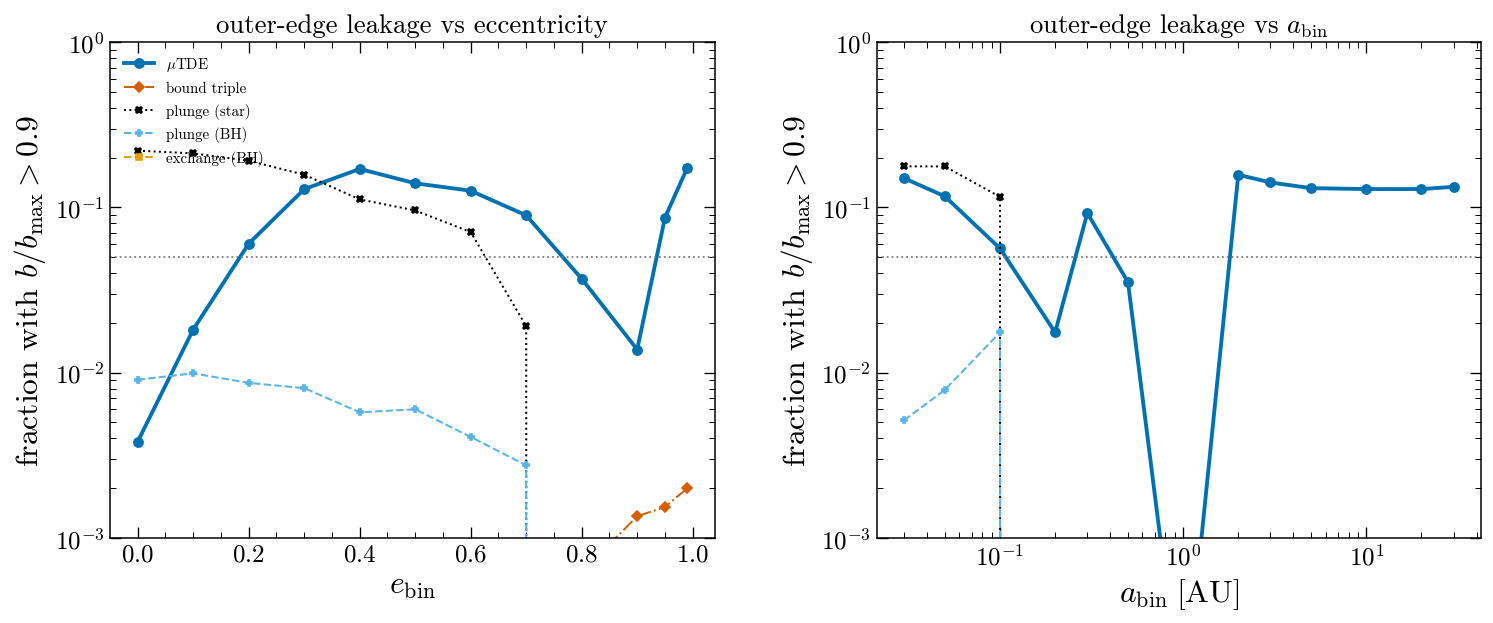

In [6]:
def leak_vs(param, nodes, kind="nodes"):
    """fraction of each channel's events with b/b_max>0.9, resolved by `param` nodes."""
    if kind == "e_nodes":
        ib = np.argmin(np.abs(param[:,None]-nodes[None,:]), axis=1)
    else:
        ib = np.argmin(np.abs(np.log10(param)[:,None]-np.log10(nodes)[None,:]), axis=1)
    out = np.full((len(nodes), NCH), np.nan)
    for j in range(len(nodes)):
        for k in range(NCH):
            sel = (ib==j) & (oidx==k); n = sel.sum()
            if n > 0: out[j,k] = np.mean(bb[sel] > 0.9)
    return out

e_nodes = np.unique(e); a_nodes = np.unique(a)
Le = leak_vs(e, e_nodes, "e_nodes"); La = leak_vs(a, a_nodes, "nodes")
show = ["muTDE","BOUND_TRIPLE","PLUNGE_star","PLUNGE_BH","EXCHANGE_BH"]
fig, ax = plt.subplots(1, 2, figsize=(13.0, 5.2))
for d in show:
    k = DISP.index(d); col,mk,ls = CH_STYLE[d]
    ax[0].plot(e_nodes, Le[:,k], marker=mk, ls=ls, color=col, lw=ch_lw(d), ms=ch_ms(d), label=CH_DISPLAY[d])
    ax[1].plot(a_nodes, La[:,k], marker=mk, ls=ls, color=col, lw=ch_lw(d), ms=ch_ms(d), label=CH_DISPLAY[d])
for axk, lab, logx in [(ax[0], r"$e_{\rm bin}$", False), (ax[1], r"$a_{\rm bin}\;[{\rm AU}]$", True)]:
    axk.axhline(0.05, color="0.5", ls=":", lw=1.1)
    if logx: axk.set_xscale("log"); log_minor(axk.xaxis)
    axk.set_yscale("log"); axk.set_ylim(1e-3, 1.0)
    axk.set_xlabel(lab); axk.set_ylabel(r"fraction with $b/b_{\max}>0.9$")
    axk.set_box_aspect(0.82)
ax[0].set_title(r"outer-edge leakage vs eccentricity"); ax[1].set_title(r"outer-edge leakage vs $a_{\rm bin}$")
ax[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout(); fig.savefig("branching_leakage_ea.png", bbox_inches="tight")
fig.savefig("branching_leakage_ea.pdf", bbox_inches="tight")
print("mu-TDE leakage at lowest vs highest e: %.3f -> %.3f" % (Le[0,DISP.index('muTDE')], Le[-1,DISP.index('muTDE')]))
plt.show()

In [7]:
# b/b_max per encounter (rp_max=10 r_t), for the leakage table below
_mtot=M+m_bin; _r_t=a*(M/m_bin)**(1.0/3.0)
_r_foc=2.0*V1*V1*_mtot/(frac*V1*np.sqrt(m_bin/a))**2
_r_g=(V1*V1/(C_KMS*C_KMS))*_mtot; _rpmax=np.maximum(10.0*_r_t,8.0*_r_g)
_bmax2=_rpmax**2+_r_foc*_rpmax
_bb=np.clip(np.sqrt(((_r_t/beta)**2+_r_foc*(_r_t/beta))/_bmax2),0.0,1.0)

print("channel      events   % beyond b/bmax=0.9   % beyond 0.8")
for d in DISP:
    k = DISP.index(d); bx = _bb[oidx == k]
    if bx.size == 0: continue
    print(f"{CH_DISPLAY[d]:16s} {bx.size:7d}   {100*(bx>0.9).mean():6.1f}            {100*(bx>0.8).mean():6.1f}")

channel      events   % beyond b/bmax=0.9   % beyond 0.8
flyby            22224906     23.1              43.5
exchange (BH)    1225718      0.0               0.0
exchange (star)  1267040      0.0               0.0
bound triple      934514      0.0               1.3
$\mu$TDE          788113     10.6              21.7
TDE (central)      71246      0.0               0.0
plunge (BH)       597662      0.6               2.8
plunge (star)     198077     14.4              37.2
ionization        326029      0.0               0.0


In [8]:
cen,C,Ntot,lab,logx = MARG["beta"]
for i in range(6):
    print(f"beta~{cen[i]:.3g}  Ntot={int(Ntot[i]):>7}  flyby={C[i,DISP.index('FLYBY')]/Ntot[i]:.3f}  "
          f"plungeBH={C[i,DISP.index('PLUNGE_BH')]/Ntot[i]:.3f}  muTDE={C[i,DISP.index('muTDE')]/Ntot[i]:.3f}")

beta~0.12  Ntot=9257006  flyby=0.979  plungeBH=0.003  muTDE=0.013
beta~0.174  Ntot=6016867  flyby=0.949  plungeBH=0.009  muTDE=0.023
beta~0.251  Ntot=3972166  flyby=0.885  plungeBH=0.016  muTDE=0.036
beta~0.363  Ntot=2655201  flyby=0.777  plungeBH=0.025  muTDE=0.045
beta~0.525  Ntot=1807075  flyby=0.556  plungeBH=0.044  muTDE=0.052
beta~0.759  Ntot=1207681  flyby=0.361  plungeBH=0.044  muTDE=0.051


In [9]:
lowb = beta < 0.1
print("N(beta<0.1):", int(lowb.sum()))
print("M_smbh values there:", np.unique(M[lowb]))
print("M_smbh values at beta>=0.1 (sample):", np.unique(M[~lowb])[:5], "...")

N(beta<0.1): 94149
M_smbh values there: [3.16228e+09 1.00000e+10]


M_smbh values at beta>=0.1 (sample): [  10.       31.6228  100.      316.228  1000.    ] ...


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_67910/2224945033.py:32: UserWarning: Glyph 8211 (\N{EN DASH}) missing from font(s) cmr10.
  fig.tight_layout(); plt.show()
Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2013' [U+2013], substituting with a dummy symbol.


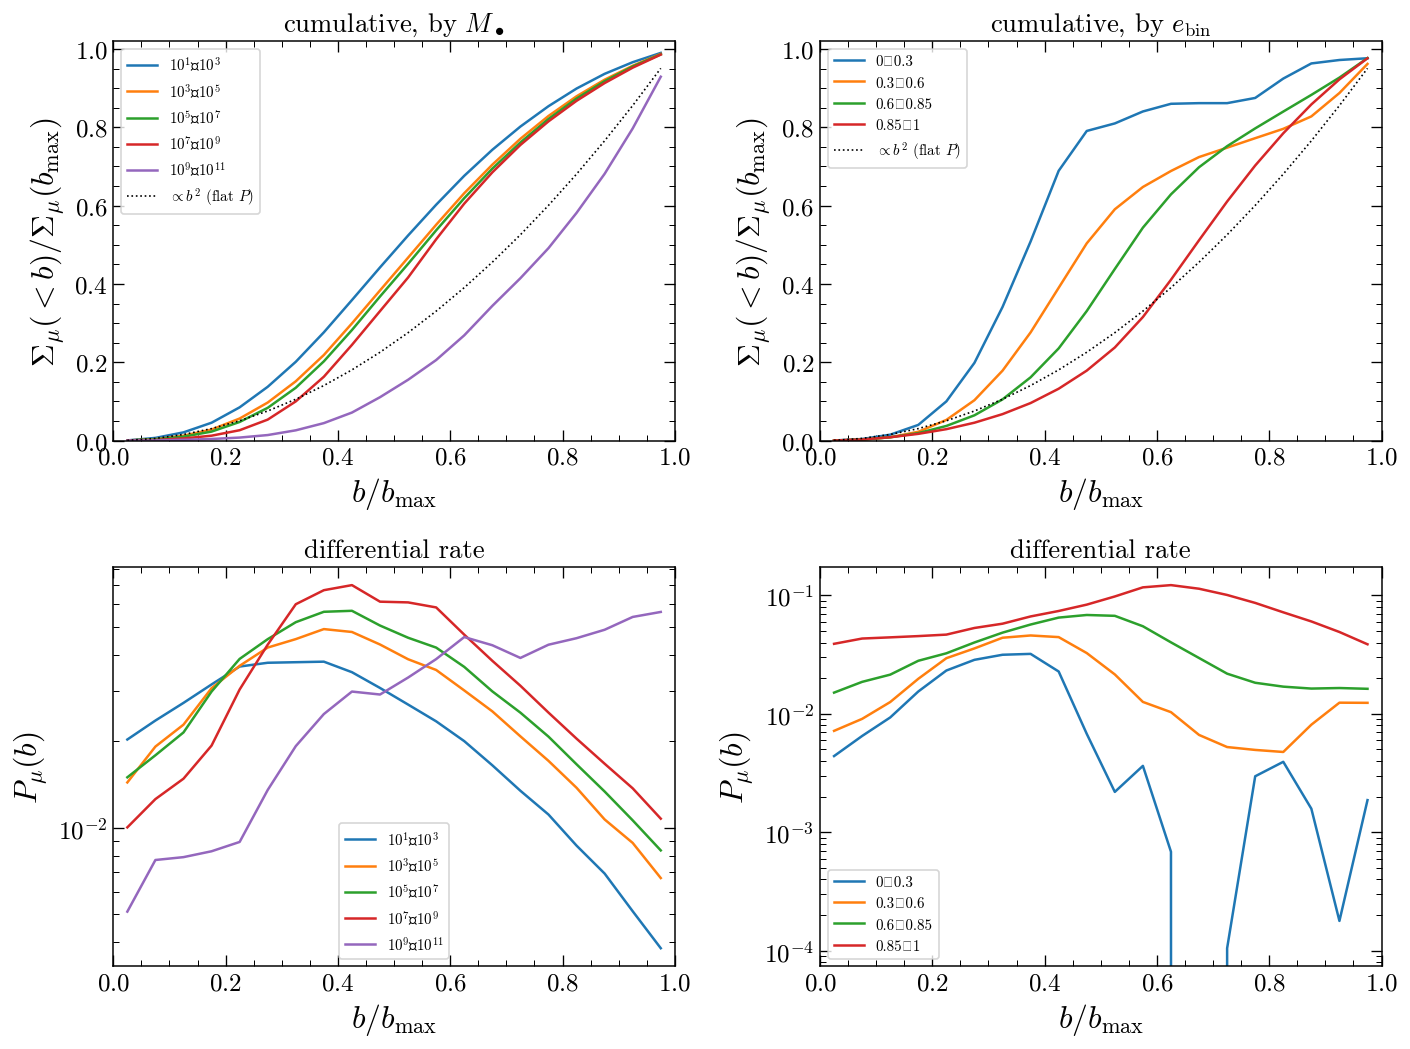

In [10]:
import numpy as np, matplotlib.pyplot as plt
imu = DISP.index("muTDE"); is_mu = (oidx == imu)
E = np.linspace(0,1,21); bc = 0.5*(E[:-1]+E[1:])

def cum_diff(mask):
    x = np.sort(_bb[mask & is_mu]); xall = _bb[mask]
    cum = np.searchsorted(x, bc, side="right")/max(x.size,1)           # sigma_mu(<b)/sigma_mu(bmax)
    nmu,_ = np.histogram(_bb[mask & is_mu], bins=E); nall,_ = np.histogram(xall, bins=E)
    P = np.where(nall>0, nmu/np.maximum(nall,1), np.nan)               # per-encounter mu-TDE prob
    return cum, P

Mg = [(1e1,1e3),(1e3,1e5),(1e5,1e7),(1e7,1e9),(1e9,1e11)]
eg = [(0,0.3),(0.3,0.6),(0.6,0.85),(0.85,1.01)]
fig, axs = plt.subplots(2,2, figsize=(12,9))
for lo,hi in Mg:
    m=(M>=lo)&(M<hi)
    if m.sum()==0: continue
    c,P=cum_diff(m); lab=rf"$10^{{{int(np.log10(lo))}}}$–$10^{{{int(np.log10(hi))}}}$"
    axs[0,0].plot(bc,c,label=lab); axs[1,0].plot(bc,P,label=lab)
for lo,hi in eg:
    m=(e>=lo)&(e<hi)
    if m.sum()==0: continue
    c,P=cum_diff(m); lab=f"{lo:.2g}–{hi:.2g}"
    axs[0,1].plot(bc,c,label=lab); axs[1,1].plot(bc,P,label=lab)
axs[0,0].set_title(r"cumulative, by $M_\bullet$"); axs[0,1].set_title(r"cumulative, by $e_{\rm bin}$")
for ax in axs[0]:
    ax.plot(bc,bc**2,"k:",lw=1,label=r"$\propto b^2$ (flat $P$)")
    ax.set_ylabel(r"$\Sigma_\mu(<b)/\Sigma_\mu(b_{\max})$"); ax.set_ylim(0,1.02)
for ax in axs[1]:
    ax.set_ylabel(r"$P_\mu(b)$"); ax.set_yscale("log"); ax.set_title("differential rate")
for ax in axs.flat: ax.set_xlabel(r"$b/b_{\max}$"); ax.set_xlim(0,1); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

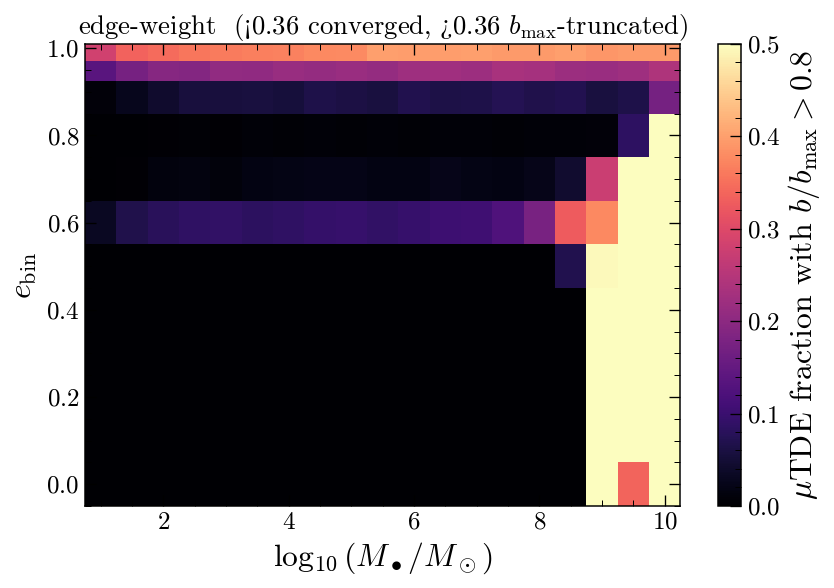

In [11]:
import numpy as np, matplotlib.pyplot as plt
Mn, en = np.unique(M), np.unique(e)
iM = np.searchsorted(Mn, M); iE = np.searchsorted(en, e)
EW = np.full((en.size, Mn.size), np.nan)
for i in range(Mn.size):
    for j in range(en.size):
        sel = is_mu & (iM==i) & (iE==j)
        if sel.sum() >= 50: EW[j,i] = np.mean(_bb[sel] > 0.8)
fig, ax = plt.subplots(figsize=(8,5))
im = ax.pcolormesh(np.log10(Mn), en, EW, shading="nearest", cmap="magma", vmin=0, vmax=0.5)
ax.set_xlabel(r"$\log_{10}(M_\bullet/M_\odot)$"); ax.set_ylabel(r"$e_{\rm bin}$")
cb = fig.colorbar(im, ax=ax); cb.set_label(r"$\mu$TDE fraction with $b/b_{\max}>0.8$")
ax.set_title(r"edge-weight  (<0.36 converged, >0.36 $b_{\max}$-truncated)")
plt.show()

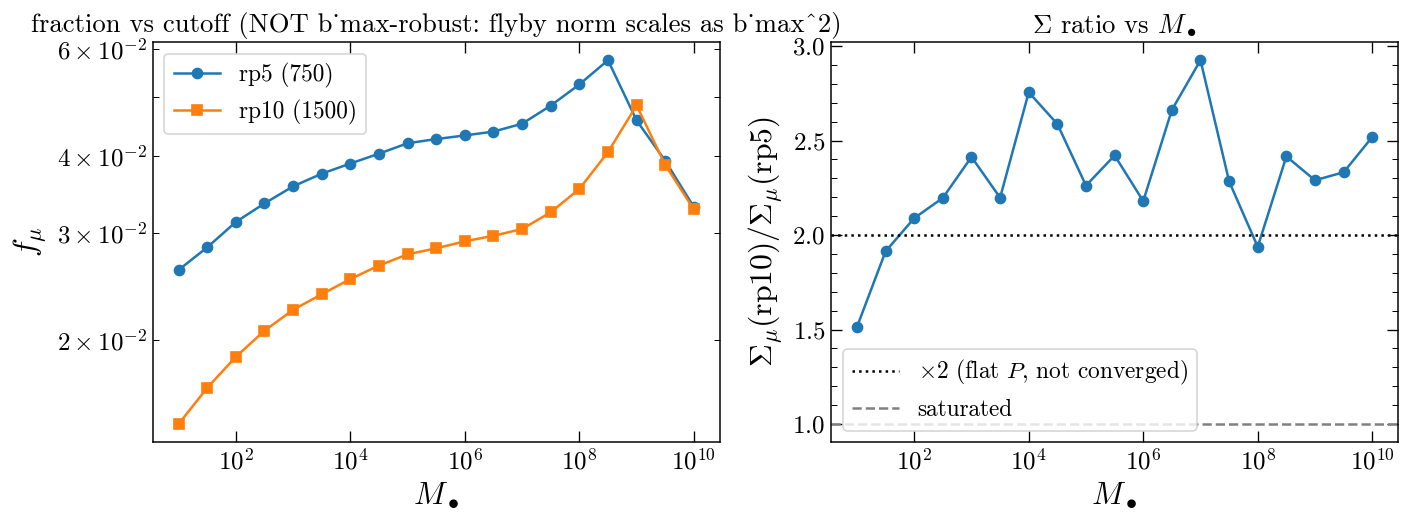

In [12]:
import numpy as np, h5py, matplotlib.pyplot as plt, collections
V1, m_bin = 29.7847, 11.0
FN = np.array([1e-3,1e-2,1e-1,3e-1,1.0,3.0,10.0])
def perM(bundle):
    with h5py.File(bundle) as f:
        R=f["results"]; M=R["M_smbh"][:]; a=R["a_bin"][:]
        mu=(R["outcome"][:].astype(str)=="TDE:star2_by_bh1"); vinf=R["v_inf"][:]
        Gm=f["grid_meta"]; gM,ga,gf,gb=(Gm["M_smbh"][:],Gm["a_bin_AU"][:],Gm["frac"][:],Gm["b_max_AU"][:])
    frac=FN[np.argmin(np.abs(np.log10(vinf/(V1*np.sqrt(m_bin/a)))[:,None]-np.log10(FN)[None,:]),1)]
    K=lambda m,x,y:(round(np.log10(m),4),round(np.log10(x),4),round(np.log10(y),4))
    bmax={K(m,x,y):b for m,x,y,b in zip(gM,ga,gf,gb)}
    Mn=np.unique(M); fM=np.zeros(Mn.size); sig=np.zeros(Mn.size)
    for i,m in enumerate(Mn):
        s=M==m; fM[i]=mu[s].mean()
        nc=collections.Counter(zip(a[s],frac[s])); nm=collections.Counter(zip(a[s][mu[s]],frac[s][mu[s]]))
        tot=0.0
        for (x,y),c in nc.items():
            b=bmax.get(K(m,x,y),np.nan)
            if np.isfinite(b): tot+=np.pi*b*b*(nm.get((x,y),0)/c)
        sig[i]=tot
    return Mn,fM,sig
import os as _os
OLD_BUNDLE = _os.environ.get("OLD_BUNDLE", "../../../data/bhstar/campaign1_rp5/smbh_bhstar_bundle_750.h5")  # first campaign (rp5, 750 real.)
NEW_BUNDLE = _os.environ.get("SMBH_BUNDLE", "../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
if not _os.path.exists(OLD_BUNDLE):
    print(f"(rp5-vs-rp10 appendix skipped: {OLD_BUNDLE} not found; set OLD_BUNDLE to the first campaign to enable)")
else:
    M5,f5,s5 = perM(OLD_BUNDLE)
    M10,f10,s10 = perM(NEW_BUNDLE)
    fig,ax=plt.subplots(1,2,figsize=(12,4.6))
    ax[0].plot(M5,f5,"o-",label="rp5 (750)"); ax[0].plot(M10,f10,"s-",label="rp10 (1500)")
    ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel(r"$M_\bullet$"); ax[0].set_ylabel(r"$f_\mu$")
    ax[0].legend(); ax[0].set_title("fraction vs cutoff (NOT b_max-robust: flyby norm scales as b_max^2)")
    ax[1].plot(M10, s10/np.interp(M10,M5,s5), "o-")
    ax[1].axhline(2.0,ls=":",c="k",label=r"$\times2$ (flat $P$, not converged)")
    ax[1].axhline(1.0,ls="--",c="grey",label="saturated")
    ax[1].set_xscale("log"); ax[1].set_xlabel(r"$M_\bullet$"); ax[1].set_ylabel(r"$\Sigma_\mu(\mathrm{rp10})/\Sigma_\mu(\mathrm{rp5})$")
    ax[1].legend(); ax[1].set_title(r"$\Sigma$ ratio vs $M_\bullet$")
    fig.tight_layout(); plt.show()
